# Items 6 and 7 from *Investigations on eunoia 0.6.0*

In [1]:
import ast
import warnings
from pathlib import Path

import eunoia as eu
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

OUT = Path("../repro-out")
OUT.mkdir(exist_ok=True)

font_manager.fontManager.addfont("fonts/IBM_Plex_Mono/IBMPlexMono-Regular.ttf")
font_manager.fontManager.addfont("fonts/Inter/Inter-Regular.ttf")


def genes(f):
    return pd.read_csv(Path("data") / f)["Gene names"].dropna().tolist()


A = genes("5. ATORVASTATIN_sample.csv")
S = genes("8. SIMVASTATIN_sample.csv")
U = genes("16. SUNITINIB_sample.csv")
fit = eu.euler({"Atorvastatin": A, "Simvastatin": S, "Sunitinib": U}, seed=1)

## Item 6: different fonts change how many members fit

[DejaVu Sans]
  Atorvastatin&Sunitinib did not fit: ['POR']
  Atorvastatin&Simvastatin did not fit: ['UGT1A9']
  Atorvastatin&Simvastatin&Sunitinib not drawn: ['CYP3A4', 'NR1I2']
  total did not fit: 2
  fonts drawn: ['DejaVu Sans']


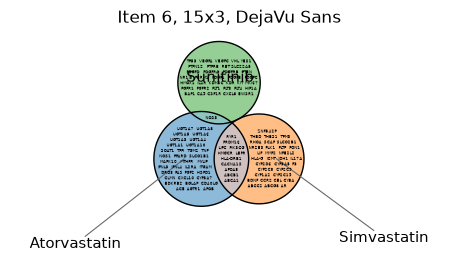

[IBM Plex Mono]
  Simvastatin did not fit: ['ZNF542P']
  Atorvastatin did not fit: ['UGT1A7', 'UGT1A8']
  Atorvastatin&Sunitinib did not fit: ['NOS3', 'POR']
  Atorvastatin&Simvastatin did not fit: ['LIPC', 'PIK3CG', 'PRDM16', 'RYR1', 'UGT1A9']
  Atorvastatin&Simvastatin&Sunitinib not drawn: ['CYP3A4', 'NR1I2']
  total did not fit: 10
  fonts drawn: ['DejaVu Sans', 'IBM Plex Mono']


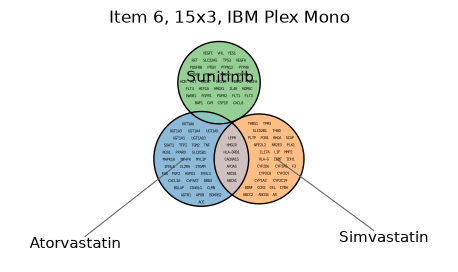

[Inter]
  Atorvastatin&Sunitinib did not fit: ['POR']
  Atorvastatin&Simvastatin did not fit: ['PRDM16', 'RYR1', 'UGT1A9']
  Atorvastatin&Simvastatin&Sunitinib not drawn: ['CYP3A4', 'NR1I2']
  total did not fit: 4
  fonts drawn: ['DejaVu Sans', 'Inter']


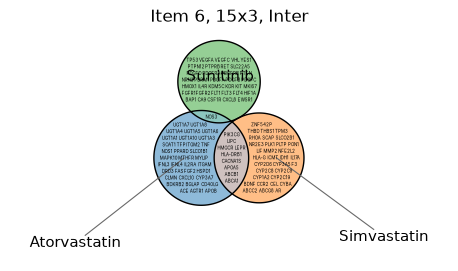

In [2]:
for font in ["DejaVu Sans", "IBM Plex Mono", "Inter"]:
    fig, ax = plt.subplots(figsize=(15, 3))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit.plot(ax=ax, members={"mode": "packed", "fontfamily": font})
    ax.set_title(f"Item 6, 15x3, {font}")

    dropped = {}
    for w in caught:
        if "did not fit" in str(w.message):
            dropped = ast.literal_eval(str(w.message).split(": ", 1)[1])

    print(f"[{font}]")
    for region, n in dropped.items():
        print(f"  {region} did not fit: {fit.members[region][-n:]}")
    for region, names in fit.members.items():
        if names and fit.fitted_values.get(region, 0) == 0:
            print(f"  {region} not drawn: {names}")
    print(f"  total did not fit: {sum(dropped.values())}")
    print(f"  fonts drawn: {sorted({t.get_fontname() for t in ax.texts})}")

    #fig.savefig(OUT / f"item6-{font.replace(' ', '-')}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Item 7: Plotly title hidden with default margins

In [ ]:
# Plotly example: 3 circles that all intersect (every region has genes).
pool = sorted(set(A + S + U))  # 118 unique genes
sizes = {"A": 35, "S": 20, "U": 15, "AS": 15, "AU": 10, "SU": 10, "ASU": 13}
chunks, i = {}, 0
for region, n in sizes.items():
    chunks[region] = pool[i : i + n]
    i += n

A7 = [g for r, c in chunks.items() if "A" in r for g in c]
S7 = [g for r, c in chunks.items() if "S" in r for g in c]
U7 = [g for r, c in chunks.items() if "U" in r for g in c]
fit7 = eu.euler({"Atorvastatin": A7, "Simvastatin": S7, "Sunitinib": U7}, seed=1)
fit7

In [ ]:
fig = fit7.plot_plotly(width=730, height=None)
fig.update_layout(title="Item 7, update_layout title")
print(f"top margin: {fig.layout.margin.t}")
fig.show()

In [ ]:
fig = fit7.plot_plotly(width=600, height=None)
fig.update_layout(title="Item 7, update_layout title", margin={"t":0})
print(f"top margin: {fig.layout.margin.t}")
fig.show()

In [ ]:
fig = fit7.plot_plotly(width=900, height=None, title="Item 7, title=")
fig.show()

In [ ]:
fig = fit7.plot_plotly(width=700, height=700, members={"mode": "packed"}, title="Item 7, 700x700")
fig.show()